Loaded 917 images belonging to 2 classes.

=============== FOLD 1/5 ===============
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 138MB/s] 


Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:02<00:00, 169MB/s]


Epoch [1/20] Train Loss: 0.5116 | Val Loss: 0.3467 | Val Acc: 0.9076
Epoch [5/20] Train Loss: 0.0804 | Val Loss: 0.1697 | Val Acc: 0.9457
Epoch [10/20] Train Loss: 0.0321 | Val Loss: 0.2456 | Val Acc: 0.9185
Early stopping triggered at epoch 13 (best val loss: 0.1598)

--- Fold 1 Classification Report (Held-out Test Set) ---
              precision    recall  f1-score   support

      Normal     0.9000    0.9184    0.9091        49
    Abnormal     0.9701    0.9630    0.9665       135

    accuracy                         0.9511       184
   macro avg     0.9351    0.9407    0.9378       184
weighted avg     0.9515    0.9511    0.9512       184

Fold 1 | AUC: 0.9943 | MCC: 0.8757 | Cohen's Kappa: 0.8756

=============== FOLD 2/5 ===============
Epoch [1/20] Train Loss: 0.4835 | Val Loss: 0.3397 | Val Acc: 0.9076
Epoch [5/20] Train Loss: 0.0745 | Val Loss: 0.1996 | Val Acc: 0.9185
Epoch [10/20] Train Loss: 0.0383 | Val Loss: 0.0838 | Val Acc: 0.9620
Epoch [15/20] Train Loss: 0.0080 | Va

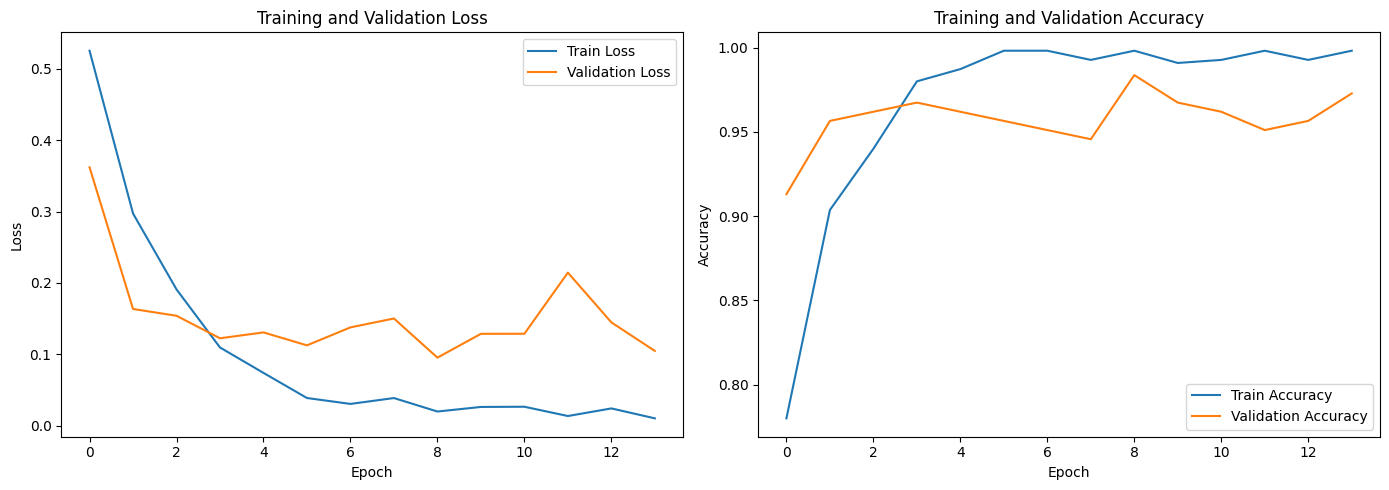

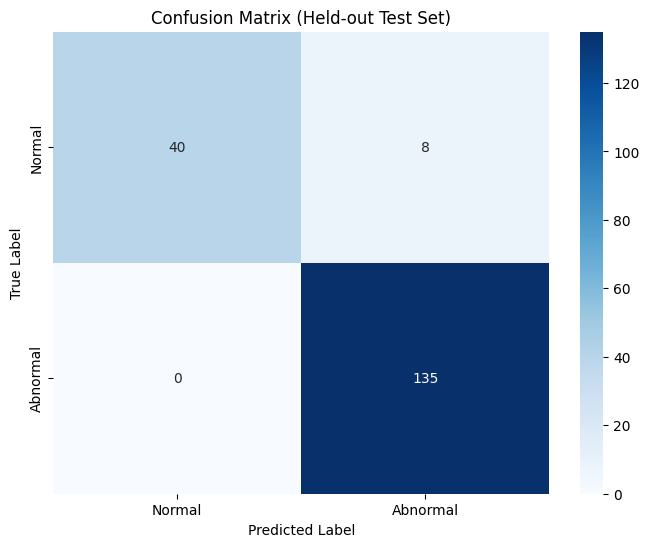

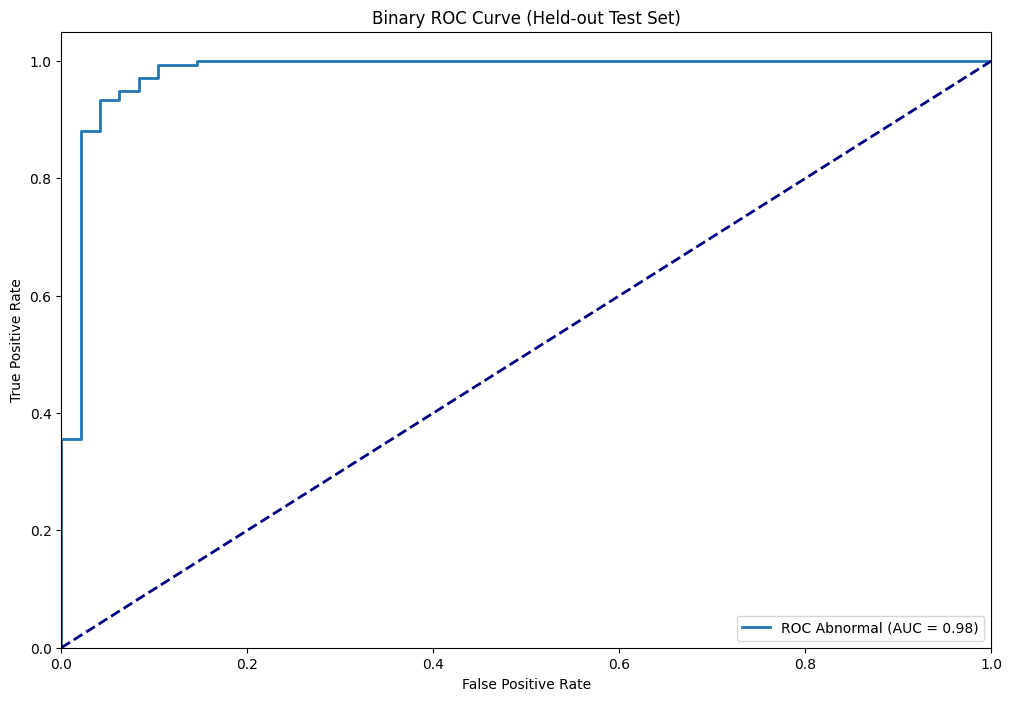

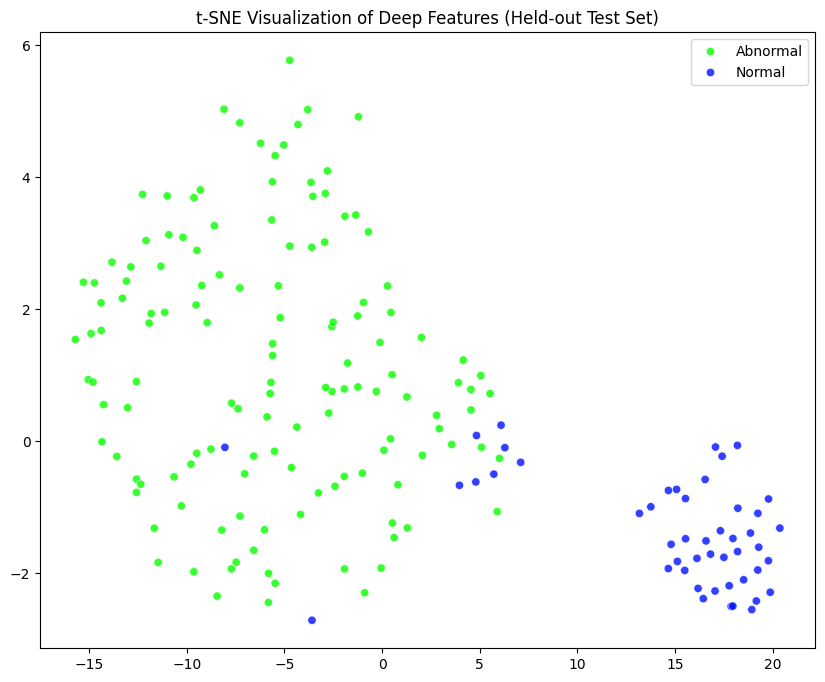

Generating LIME Explanation for true class: Normal...


  0%|          | 0/500 [00:00<?, ?it/s]

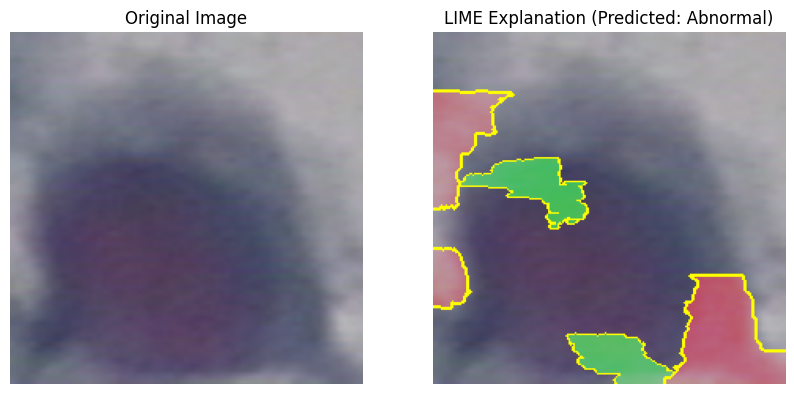

Generating LIME Explanation for true class: Abnormal...


  0%|          | 0/500 [00:00<?, ?it/s]

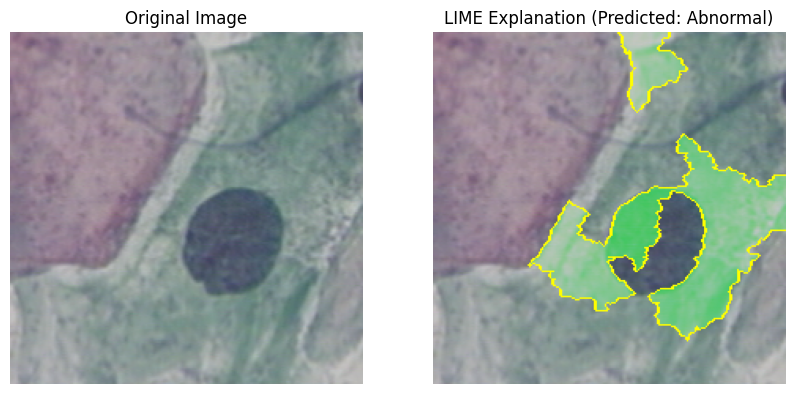


==================== OVERALL 5-FOLD CV RESULTS (ON HELD-OUT TEST SETS) ====================
Accuracy  : 95.53 ± 1.05e-02
Precision : 95.49 ± 1.66e-02
Recall    : 92.99 ± 1.68e-02
F-score   : 94.09 ± 1.37e-02
AUC       : 99.13 ± 5.76e-03
MCC       : 88.42 ± 2.71e-02
Kappa     : 88.20 ± 2.74e-02

==================== INFERENCE SPEED ====================
Avg Test Time per Fold    : 2.6006 seconds
Avg Test Time Per Image   : 0.01418 seconds/image


In [ ]:
"""
CSF-Net: Cascaded Stage-wise Gated Fusion Network for Cervical Cytology Classification
=========================================================================================

Design (novel relative to the CNN/Trans/DIFF-block baseline it is compared against):
  - CNN stream:  pretrained EfficientNet-B0 (ImageNet), tapped at 4 stage depths.
                 EfficientNet-B0 is chosen over DenseNet-121 here because its
                 inverted-residual/SE blocks give a smoother, more parameter-efficient
                 channel progression across exactly 4 usable stage taps, which lines up
                 naturally with a 4-stage fusion cascade (DenseNet's growth-rate
                 concatenation makes the later stages very high-dimensional and would
                 need extra bottlenecking before fusion).
  - Trans stream: pretrained ViT-B/16 (ImageNet), tapped after encoder layers
                 {3, 6, 9, 12}. Token sequences (minus the CLS token) are reshaped back
                 into 14x14 spatial maps so they can be fused with CNN feature maps.
  - Fusion:      GatedCrossFusion -- at each of the 4 stages, CNN and ViT features are
                 projected to a common dim/resolution, bidirectionally re-weighted by
                 each other's global (squeeze-excite style) context, concatenated and
                 merged by a 3x3 conv. Critically, each stage's fused output is added
                 to the *previous* stage's fused output (a cascaded residual carry-over),
                 so stage 4's representation is informed by the whole fusion history.
                 This replaces the baseline's plain concat -> two 1x1-conv "DIFF unit"
                 with a bidirectional gating + cascading mechanism.
  - Both backbones are partially frozen (early layers) and fine-tuned end-to-end with
    a lower learning rate than the fusion head, which is standard practice when
    adapting ImageNet backbones to a small medical-imaging dataset.

"""

import os
import glob
import cv2
import time
import copy
import warnings
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, matthews_corrcoef, cohen_kappa_score,
                             confusion_matrix, roc_curve, auc, classification_report)
from sklearn.manifold import TSNE

# For LIME
try:
    from lime import lime_image
    from skimage.segmentation import mark_boundaries
    LIME_AVAILABLE = True
except ImportError:
    LIME_AVAILABLE = False
    print("Warning: LIME is not installed. Please run '!pip install lime' to generate LIME plots.")

warnings.filterwarnings('ignore')


# ==========================================
# 1. Configuration & Hyperparameters
# ==========================================
class Config:
    DATASET_PATH = '/kaggle/input/datasets/yuvrajsinhachowdhury/herlev-dataset/Herlev Dataset'
    IMG_SIZE = 224                 # required by pretrained ViT-B/16 / EfficientNet-B0
    NUM_CLASSES = 2
    BATCH_SIZE = 16
    EPOCHS = 20                   # early stopping will typically halt well before this
    BACKBONE_LR = 1e-5             # small LR for pretrained backbones
    HEAD_LR = 1e-4                 # larger LR for fusion + classifier head
    WEIGHT_DECAY = 1e-4
    NUM_FOLDS = 5
    NUM_FUSION_STAGES = 4
    FUSION_DIM = 128
    EARLY_STOP_PATIENCE = 5
    FREEZE_CNN_STAGES = 2          # freeze first N EfficientNet stages
    FREEZE_TRANS_LAYERS = 3        # freeze first N ViT encoder blocks
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

config = Config()


# ==========================================
# 2. Data Loading & PyTorch Dataset
# ==========================================
def load_herlev_data():
    class_folders = [
        'carcinoma_in_situ', 'light_dysplastic', 'moderate_dysplastic',
        'normal_columnar', 'normal_intermediate', 'normal_superficiel', 'severe_dysplastic'
    ]

    folder_to_binary_idx = {
        'carcinoma_in_situ': 1,
        'light_dysplastic': 1,
        'moderate_dysplastic': 1,
        'severe_dysplastic': 1,
        'normal_columnar': 0,
        'normal_intermediate': 0,
        'normal_superficiel': 0
    }

    binary_class_names = ['Normal', 'Abnormal']

    X, y = [], []

    for split in ['train', 'test']:
        for class_folder in class_folders:
            folder_path = os.path.join(config.DATASET_PATH, split, class_folder)
            if not os.path.exists(folder_path):
                continue

            image_paths = glob.glob(os.path.join(folder_path, '*.*'))
            for img_path in image_paths:
                img = cv2.imread(img_path)
                if img is None:
                    continue
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                img = cv2.resize(img, (config.IMG_SIZE, config.IMG_SIZE))
                X.append(img)
                y.append(folder_to_binary_idx[class_folder])

    return np.array(X, dtype=np.uint8), np.array(y), binary_class_names


class HerlevDataset(Dataset):
    def __init__(self, X, y, transform=None):
        self.X = X
        self.y = y
        self.transform = transform

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        img = Image.fromarray(self.X[idx])
        label = self.y[idx]
        if self.transform:
            img = self.transform(img)
        return img, label


# ==========================================
# 3. Model Architecture (Pretrained CNN + Pretrained ViT + Cascaded Gated Fusion)
# ==========================================
class EfficientNetBranch(nn.Module):
    """Pretrained EfficientNet-B0 CNN stream, tapped at 4 stage depths."""

    def __init__(self, pretrained=True, stage_indices=(2, 4, 6, 8), freeze_stages=2):
        super().__init__()
        weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
        effnet = models.efficientnet_b0(weights=weights)
        self.features = effnet.features          # nn.Sequential of 9 stage blocks
        self.stage_indices = stage_indices

        for i, layer in enumerate(self.features):
            if i < freeze_stages:
                for p in layer.parameters():
                    p.requires_grad = False

    def forward(self, x):
        feats = []
        for i, layer in enumerate(self.features):
            x = layer(x)
            if i in self.stage_indices:
                feats.append(x)
        return feats


class ViTBranch(nn.Module):
    """Pretrained ViT-B/16 transformer stream, tapped after 4 encoder blocks."""

    def __init__(self, pretrained=True, layer_indices=(3, 6, 9, 12), freeze_layers=3):
        super().__init__()
        weights = models.ViT_B_16_Weights.IMAGENET1K_V1 if pretrained else None
        vit = models.vit_b_16(weights=weights)

        self.conv_proj = vit.conv_proj
        self.class_token = vit.class_token
        self.pos_embedding = vit.encoder.pos_embedding
        self.dropout = vit.encoder.dropout
        self.layers = vit.encoder.layers          # nn.Sequential of 12 EncoderBlocks
        self.layer_indices = layer_indices

        for i, blk in enumerate(self.layers):
            if i < freeze_layers:
                for p in blk.parameters():
                    p.requires_grad = False

    def forward(self, x):
        n = x.shape[0]
        x = self.conv_proj(x)                                  # B, D, H', W'
        d = x.shape[1]
        x = x.reshape(n, d, -1).permute(0, 2, 1)                # B, N, D
        cls_token = self.class_token.expand(n, -1, -1)
        x = torch.cat([cls_token, x], dim=1)                    # B, N+1, D
        x = x + self.pos_embedding
        x = self.dropout(x)

        feats = []
        for i, blk in enumerate(self.layers, start=1):
            x = blk(x)
            if i in self.layer_indices:
                tokens = x[:, 1:, :]                            # drop CLS token
                B, N, D = tokens.shape
                H = W = int(round(N ** 0.5))
                fmap = tokens.permute(0, 2, 1).reshape(B, D, H, W)
                feats.append(fmap)
        return feats


class GatedCrossFusion(nn.Module):
    """
    Novel fusion unit (replaces the baseline's plain concat + 1x1-conv DIFF unit).

    At each stage: project CNN and Trans features to a shared dim/resolution,
    bidirectionally gate each stream using the other's squeeze-excite-style global
    context, merge with a 3x3 conv, then add the *previous* stage's fused output
    (cascaded residual carry-over) so information accumulates across stages.
    """

    def __init__(self, cnn_channels, trans_channels, fusion_dim=128, has_prev=False, out_size=7):
        super().__init__()
        self.out_size = out_size

        self.cnn_proj = nn.Sequential(
            nn.Conv2d(cnn_channels, fusion_dim, kernel_size=1, bias=False),
            nn.BatchNorm2d(fusion_dim), nn.ReLU(inplace=True)
        )
        self.trans_proj = nn.Sequential(
            nn.Conv2d(trans_channels, fusion_dim, kernel_size=1, bias=False),
            nn.BatchNorm2d(fusion_dim), nn.ReLU(inplace=True)
        )

        self.gate_from_trans = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Conv2d(fusion_dim, fusion_dim, 1), nn.Sigmoid()
        )
        self.gate_from_cnn = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Conv2d(fusion_dim, fusion_dim, 1), nn.Sigmoid()
        )

        self.merge = nn.Sequential(
            nn.Conv2d(fusion_dim * 2, fusion_dim, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(fusion_dim), nn.ReLU(inplace=True)
        )

        self.prev_proj = None
        if has_prev:
            self.prev_proj = nn.Sequential(
                nn.Conv2d(fusion_dim, fusion_dim, kernel_size=1, bias=False),
                nn.BatchNorm2d(fusion_dim), nn.ReLU(inplace=True)
            )

    def forward(self, cnn_feat, trans_feat, prev_fused=None):
        cnn_feat = F.adaptive_avg_pool2d(cnn_feat, self.out_size)
        trans_feat = F.adaptive_avg_pool2d(trans_feat, self.out_size)

        c = self.cnn_proj(cnn_feat)
        t = self.trans_proj(trans_feat)

        c_gated = c * self.gate_from_trans(t)
        t_gated = t * self.gate_from_cnn(c)

        fused = self.merge(torch.cat([c_gated, t_gated], dim=1))

        if prev_fused is not None and self.prev_proj is not None:
            fused = fused + self.prev_proj(prev_fused)

        return fused


class CSFNet(nn.Module):
    """Cascaded Stage-wise Gated Fusion Network (pretrained EfficientNet-B0 + ViT-B/16)."""

    def __init__(self, num_classes=2, fusion_dim=128, num_stages=4, pretrained=True,
                 freeze_cnn_stages=2, freeze_trans_layers=3):
        super().__init__()
        self.num_stages = num_stages
        self.cnn_branch = EfficientNetBranch(pretrained=pretrained, freeze_stages=freeze_cnn_stages)
        self.trans_branch = ViTBranch(pretrained=pretrained, freeze_layers=freeze_trans_layers)

        with torch.no_grad():
            dummy = torch.randn(1, 3, 224, 224)
            cnn_feats = self.cnn_branch(dummy)
            trans_feats = self.trans_branch(dummy)
        cnn_channels = [f.shape[1] for f in cnn_feats]
        trans_channels = [f.shape[1] for f in trans_feats]
        assert len(cnn_channels) == num_stages and len(trans_channels) == num_stages, \
            "Mismatch between number of tapped stages and NUM_FUSION_STAGES"

        self.fusion_blocks = nn.ModuleList([
            GatedCrossFusion(cnn_channels[i], trans_channels[i], fusion_dim, has_prev=(i > 0))
            for i in range(num_stages)
        ])

        self.avgpool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Linear(fusion_dim, fusion_dim // 2),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(fusion_dim // 2, num_classes)
        )

    def forward(self, x, return_features=False):
        cnn_feats = self.cnn_branch(x)
        trans_feats = self.trans_branch(x)

        fused = None
        for i in range(self.num_stages):
            fused = self.fusion_blocks[i](cnn_feats[i], trans_feats[i], fused)

        pooled = self.avgpool(fused).flatten(1)
        logits = self.classifier(pooled)

        if return_features:
            return logits, pooled
        return logits

    def backbone_and_head_param_groups(self, backbone_lr, head_lr, weight_decay):
        backbone_params = list(self.cnn_branch.parameters()) + list(self.trans_branch.parameters())
        head_params = list(self.fusion_blocks.parameters()) + list(self.classifier.parameters())
        return [
            {'params': [p for p in backbone_params if p.requires_grad], 'lr': backbone_lr},
            {'params': [p for p in head_params if p.requires_grad], 'lr': head_lr},
        ], weight_decay


# ==========================================
# 4. Early Stopping
# ==========================================
class EarlyStopping:
    def __init__(self, patience=10, min_delta=1e-4):
        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = np.inf
        self.counter = 0
        self.best_state = None
        self.stop = False

    def step(self, val_loss, model):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
            self.best_state = copy.deepcopy(model.state_dict())
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.stop = True

    def restore_best(self, model):
        if self.best_state is not None:
            model.load_state_dict(self.best_state)


# ==========================================
# 5. Visualizations & Interpretability
# ==========================================
def plot_training_curves(history):
    plt.figure(figsize=(14, 5))
    plt.subplot(1, 2, 1)
    plt.plot(history['train_loss'], label='Train Loss')
    plt.plot(history['val_loss'], label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history['train_acc'], label='Train Accuracy')
    plt.plot(history['val_acc'], label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.tight_layout()
    plt.show()


def plot_confusion_matrix(y_true, y_pred, classes):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
    plt.title('Confusion Matrix (Held-out Test Set)')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()


def plot_roc_curve(y_true, y_probs, num_classes, class_names):
    plt.figure(figsize=(12, 8))

    fpr, tpr, _ = roc_curve(y_true, y_probs[:, 1])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f'ROC {class_names[1]} (AUC = {roc_auc:.2f})')

    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Binary ROC Curve (Held-out Test Set)')
    plt.legend(loc="lower right")
    plt.show()


def plot_tsne(features, labels, class_names):
    tsne = TSNE(n_components=2, random_state=42)
    tsne_results = tsne.fit_transform(features)

    plt.figure(figsize=(10, 8))
    sns.scatterplot(
        x=tsne_results[:, 0], y=tsne_results[:, 1],
        hue=[class_names[l] for l in labels],
        palette=sns.color_palette("hsv", len(class_names)),
        legend="full", alpha=0.8
    )
    plt.title('t-SNE Visualization of Deep Features (Held-out Test Set)')
    plt.show()


def generate_lime_explanation(model, image_np, transform_fn, device, class_names):
    if not LIME_AVAILABLE:
        return

    explainer = lime_image.LimeImageExplainer()

    def predict_fn(images):
        model.eval()
        batch_tensors = [transform_fn(Image.fromarray(img.astype(np.uint8))) for img in images]
        batch = torch.stack(batch_tensors).to(device)
        with torch.no_grad():
            logits = model(batch)
            probs = F.softmax(logits, dim=1)
        return probs.cpu().numpy()

    explanation = explainer.explain_instance(image_np, predict_fn, top_labels=1, hide_color=0, num_samples=500)

    temp, mask = explanation.get_image_and_mask(explanation.top_labels[0], positive_only=False, num_features=5, hide_rest=False)

    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(image_np)
    plt.title('Original Image')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(mark_boundaries(temp, mask))
    plt.title(f'LIME Explanation (Predicted: {class_names[explanation.top_labels[0]]})')
    plt.axis('off')
    plt.show()


# ==========================================
# 6. Main Execution & Train/Val/Test CV
# ==========================================
if __name__ == "__main__":
    X, y, classes = load_herlev_data()
    print(f"Loaded {len(X)} images belonging to {len(classes)} classes.")

    skf = StratifiedKFold(n_splits=config.NUM_FOLDS, shuffle=True, random_state=42)

    results = {'acc': [], 'prec': [], 'rec': [], 'f1': [], 'auc': [], 'mcc': [], 'kappa': []}
    infer_times_total, infer_times_per_img = [], []

    # ImageNet normalization statistics, required for pretrained EfficientNet / ViT
    IMAGENET_MEAN = [0.485, 0.456, 0.406]
    IMAGENET_STD = [0.229, 0.224, 0.225]

    train_transform = transforms.Compose([
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(10),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
    ])

    eval_transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
    ])

    for fold, (train_val_idx, test_idx) in enumerate(skf.split(X, y)):
        print(f"\n{'='*15} FOLD {fold+1}/{config.NUM_FOLDS} {'='*15}")

        X_test, y_test = X[test_idx], y[test_idx]

        X_train_val, y_train_val = X[train_val_idx], y[train_val_idx]
        X_train, X_val, y_train, y_val = train_test_split(
            X_train_val, y_train_val, test_size=0.25, stratify=y_train_val, random_state=42
        )

        train_loader = DataLoader(HerlevDataset(X_train, y_train, train_transform), batch_size=config.BATCH_SIZE, shuffle=True, num_workers=2)
        val_loader = DataLoader(HerlevDataset(X_val, y_val, eval_transform), batch_size=config.BATCH_SIZE, shuffle=False, num_workers=2)
        test_loader = DataLoader(HerlevDataset(X_test, y_test, eval_transform), batch_size=config.BATCH_SIZE, shuffle=False, num_workers=2)

        model = CSFNet(
            num_classes=config.NUM_CLASSES,
            fusion_dim=config.FUSION_DIM,
            num_stages=config.NUM_FUSION_STAGES,
            pretrained=True,
            freeze_cnn_stages=config.FREEZE_CNN_STAGES,
            freeze_trans_layers=config.FREEZE_TRANS_LAYERS
        ).to(config.DEVICE)

        criterion = nn.CrossEntropyLoss()
        param_groups, weight_decay = model.backbone_and_head_param_groups(
            config.BACKBONE_LR, config.HEAD_LR, config.WEIGHT_DECAY
        )
        optimizer = optim.AdamW(param_groups, weight_decay=weight_decay)
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=4)

        early_stopper = EarlyStopping(patience=config.EARLY_STOP_PATIENCE)
        history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

        # Training Phase (with early stopping)
        for epoch in range(config.EPOCHS):
            model.train()
            r_loss, r_correct, total = 0.0, 0, 0
            for imgs, labels in train_loader:
                imgs, labels = imgs.to(config.DEVICE), labels.to(config.DEVICE)
                optimizer.zero_grad()
                outputs = model(imgs)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()
                r_loss += loss.item() * imgs.size(0)
                r_correct += (torch.max(outputs, 1)[1] == labels).sum().item()
                total += labels.size(0)

            history['train_loss'].append(r_loss / total)
            history['train_acc'].append(r_correct / total)

            model.eval()
            v_loss, v_correct, v_total = 0.0, 0, 0
            with torch.no_grad():
                for imgs, labels in val_loader:
                    imgs, labels = imgs.to(config.DEVICE), labels.to(config.DEVICE)
                    outputs = model(imgs)
                    v_loss += criterion(outputs, labels).item() * imgs.size(0)
                    v_correct += (torch.max(outputs, 1)[1] == labels).sum().item()
                    v_total += labels.size(0)

            epoch_val_loss = v_loss / v_total
            history['val_loss'].append(epoch_val_loss)
            history['val_acc'].append(v_correct / v_total)

            scheduler.step(epoch_val_loss)
            early_stopper.step(epoch_val_loss, model)

            if (epoch + 1) % 5 == 0 or epoch == 0:
                print(f"Epoch [{epoch+1}/{config.EPOCHS}] Train Loss: {history['train_loss'][-1]:.4f} | "
                      f"Val Loss: {epoch_val_loss:.4f} | Val Acc: {history['val_acc'][-1]:.4f}")

            if early_stopper.stop:
                print(f"Early stopping triggered at epoch {epoch+1} (best val loss: {early_stopper.best_loss:.4f})")
                break

        # Restore best checkpoint before final evaluation
        early_stopper.restore_best(model)

        # Final HELD-OUT TEST SET Evaluation
        model.eval()
        all_preds, all_labels, all_probs, all_feats = [], [], [], []

        start_time = time.time()
        with torch.no_grad():
            for imgs, labels in test_loader:
                imgs = imgs.to(config.DEVICE)
                logits, feats = model(imgs, return_features=True)
                probs = F.softmax(logits, dim=1)

                all_preds.extend(torch.max(logits, 1)[1].cpu().numpy())
                all_probs.extend(probs.cpu().numpy())
                all_labels.extend(labels.numpy())
                all_feats.extend(feats.cpu().numpy())

        end_time = time.time()
        fold_infer_total = end_time - start_time
        fold_infer_per_img = fold_infer_total / len(all_labels)
        infer_times_total.append(fold_infer_total)
        infer_times_per_img.append(fold_infer_per_img)

        # Metric Collection
        all_probs = np.array(all_probs)
        fold_acc = accuracy_score(all_labels, all_preds)
        fold_prec = precision_score(all_labels, all_preds, average='macro', zero_division=0)
        fold_rec = recall_score(all_labels, all_preds, average='macro', zero_division=0)
        fold_f1 = f1_score(all_labels, all_preds, average='macro', zero_division=0)
        fold_auc = roc_auc_score(all_labels, all_probs[:, 1])
        fold_mcc = matthews_corrcoef(all_labels, all_preds)
        fold_kappa = cohen_kappa_score(all_labels, all_preds)

        results['acc'].append(fold_acc)
        results['prec'].append(fold_prec)
        results['rec'].append(fold_rec)
        results['f1'].append(fold_f1)
        results['auc'].append(fold_auc)
        results['mcc'].append(fold_mcc)
        results['kappa'].append(fold_kappa)

        # Per-fold classification report + extra metrics
        print(f"\n--- Fold {fold+1} Classification Report (Held-out Test Set) ---")
        print(classification_report(all_labels, all_preds, target_names=classes, zero_division=0, digits=4))
        print(f"Fold {fold+1} | AUC: {fold_auc:.4f} | MCC: {fold_mcc:.4f} | Cohen's Kappa: {fold_kappa:.4f}")

        # Visualizations (Executed on the LAST fold's Test Set)
        if fold == config.NUM_FOLDS - 1:
            print("\nGenerating Visualizations on the Held-out Test Set...")
            plot_training_curves(history)
            plot_confusion_matrix(all_labels, all_preds, classes)
            plot_roc_curve(all_labels, all_probs, config.NUM_CLASSES, classes)
            plot_tsne(np.array(all_feats), all_labels, classes)

            for cls_idx in range(config.NUM_CLASSES):
                cls_indices = np.where(y_test == cls_idx)[0]
                if len(cls_indices) > 0:
                    random_idx = np.random.choice(cls_indices)
                    print(f"Generating LIME Explanation for true class: {classes[cls_idx]}...")
                    generate_lime_explanation(model, X_test[random_idx], eval_transform, config.DEVICE, classes)

        del model, optimizer, train_loader, val_loader, test_loader
        torch.cuda.empty_cache()

    # ==========================================
    # Final Output Statistics
    # ==========================================
    print(f"\n{'='*20} OVERALL 5-FOLD CV RESULTS (ON HELD-OUT TEST SETS) {'='*20}")

    def format_metric(metric_list):
        mean_val = np.mean(metric_list) * 100
        std_val = np.std(metric_list)
        return f"{mean_val:.2f} ± {std_val:.2e}"

    print(f"Accuracy  : {format_metric(results['acc'])}")
    print(f"Precision : {format_metric(results['prec'])}")
    print(f"Recall    : {format_metric(results['rec'])}")
    print(f"F-score   : {format_metric(results['f1'])}")
    print(f"AUC       : {format_metric(results['auc'])}")
    print(f"MCC       : {format_metric(results['mcc'])}")
    print(f"Kappa     : {format_metric(results['kappa'])}")

    print(f"\n{'='*20} INFERENCE SPEED {'='*20}")
    print(f"Avg Test Time per Fold    : {np.mean(infer_times_total):.4f} seconds")
    print(f"Avg Test Time Per Image   : {np.mean(infer_times_per_img):.5f} seconds/image")